In [ ]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from knndbscan import knn_dbscan
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons


def run_benchmark(
    X,
    dataset_name,
    n_clusters,
    eps,
    min_samples,
    seed=0,
    figs_dir: Path | None = None,
):
    print(f"\n{'=' * 20} Benchmarking on {dataset_name} {'=' * 20}")
    print(f"Data shape: {X.shape}")

    results = []
    labels_dict = {}

    # --- KMeans ---
    print(f"Running KMeans (k={n_clusters})...")
    start = time.perf_counter()
    kmeans = KMeans(n_clusters=n_clusters, random_state=seed, n_init="auto")
    labels_kmeans = kmeans.fit_predict(X)
    duration_kmeans = time.perf_counter() - start

    n_clus_km = len(np.unique(labels_kmeans))
    noise_km = 0  # KMeans doesn't have noise

    results.append(
        {
            "Algorithm": "KMeans",
            "Time (s)": duration_kmeans,
            "Clusters": n_clus_km,
            "Noise Points": noise_km,
        }
    )
    labels_dict["KMeans"] = labels_kmeans

    # --- DBSCAN (sklearn) ---
    print(f"Running DBSCAN (sklearn) [eps={eps}, min_samples={min_samples}]...")
    start = time.perf_counter()
    dbscan = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
    labels_dbscan = dbscan.fit_predict(X)
    duration_dbscan = time.perf_counter() - start

    n_clus_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
    noise_db = list(labels_dbscan).count(-1)

    results.append(
        {
            "Algorithm": "DBSCAN (sklearn)",
            "Time (s)": duration_dbscan,
            "Clusters": n_clus_db,
            "Noise Points": noise_db,
        }
    )
    labels_dict["DBSCAN (sklearn)"] = labels_dbscan

    # --- knndbscan ---
    print(f"Running knndbscan [eps={eps}, min_samples={min_samples}]...")
    start = time.perf_counter()
    labels_knn = knn_dbscan(
        X, eps=eps, min_samples=min_samples, n_jobs=-1, device="cpu"
    )
    duration_knn = time.perf_counter() - start

    n_clus_knn = len(set(labels_knn)) - (1 if -1 in labels_knn else 0)
    noise_knn = list(labels_knn).count(-1)

    results.append(
        {
            "Algorithm": "knndbscan",
            "Time (s)": duration_knn,
            "Clusters": n_clus_knn,
            "Noise Points": noise_knn,
        }
    )
    labels_dict["knndbscan"] = labels_knn

    # --- Print summary table ---
    print("\nBenchmark Results:")
    print(f"{'Algorithm':<20} {'Time (s)':>10} {'Clusters':>10} {'Noise Points':>15}")
    print("-" * 60)
    for res in results:
        print(
            f"{res['Algorithm']:<20} {res['Time (s)']:>10.4f} {res['Clusters']:>10} {res['Noise Points']:>15}"
        )

    # --- Plotting ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # KMeans
    axes[0].scatter(X[:, 0], X[:, 1], c=labels_dict["KMeans"], cmap="viridis", s=10)
    axes[0].set_title(f"KMeans (time: {duration_kmeans:.4f}s)")

    # DBSCAN
    axes[1].scatter(
        X[:, 0], X[:, 1], c=labels_dict["DBSCAN (sklearn)"], cmap="viridis", s=10
    )
    axes[1].set_title(f"sklearn DBSCAN (time: {duration_dbscan:.4f}s)")

    # knndbscan
    axes[2].scatter(X[:, 0], X[:, 1], c=labels_dict["knndbscan"], cmap="viridis", s=10)
    axes[2].set_title(f"knndbscan (time: {duration_knn:.4f}s)")

    plt.suptitle(f"Clustering Comparison: {dataset_name}")
    plt.tight_layout()

    fig_base_name = f"comparison_{dataset_name.lower().replace(' ', '_')}.png"
    if isinstance(figs_dir, Path):
        figs_dir.mkdir(parents=True, exist_ok=True)
        fig_fname = figs_dir / fig_base_name
    else:
        fig_fname = fig_base_name
    plt.savefig(fig_fname)
    print(f"\nPlot saved to {fig_fname}")
    plt.show()
    return labels_kmeans, labels_dbscan, labels_knn

Generating Blobs...

==================== Benchmarking on Blobs ====================
Data shape: (30000, 2)
Running KMeans (k=5)...
Running DBSCAN (sklearn) [eps=0.5, min_samples=300]...
Running knndbscan [eps=0.5, min_samples=300]...

Benchmark Results:
Algorithm              Time (s)   Clusters    Noise Points
------------------------------------------------------------
KMeans                   0.1245          5               0
DBSCAN (sklearn)         0.2355          5             153
knndbscan                1.8102          5             153

Plot saved to /home/prajwal/github-repos/hatann/_experiments/figures/comparison_blobs.png


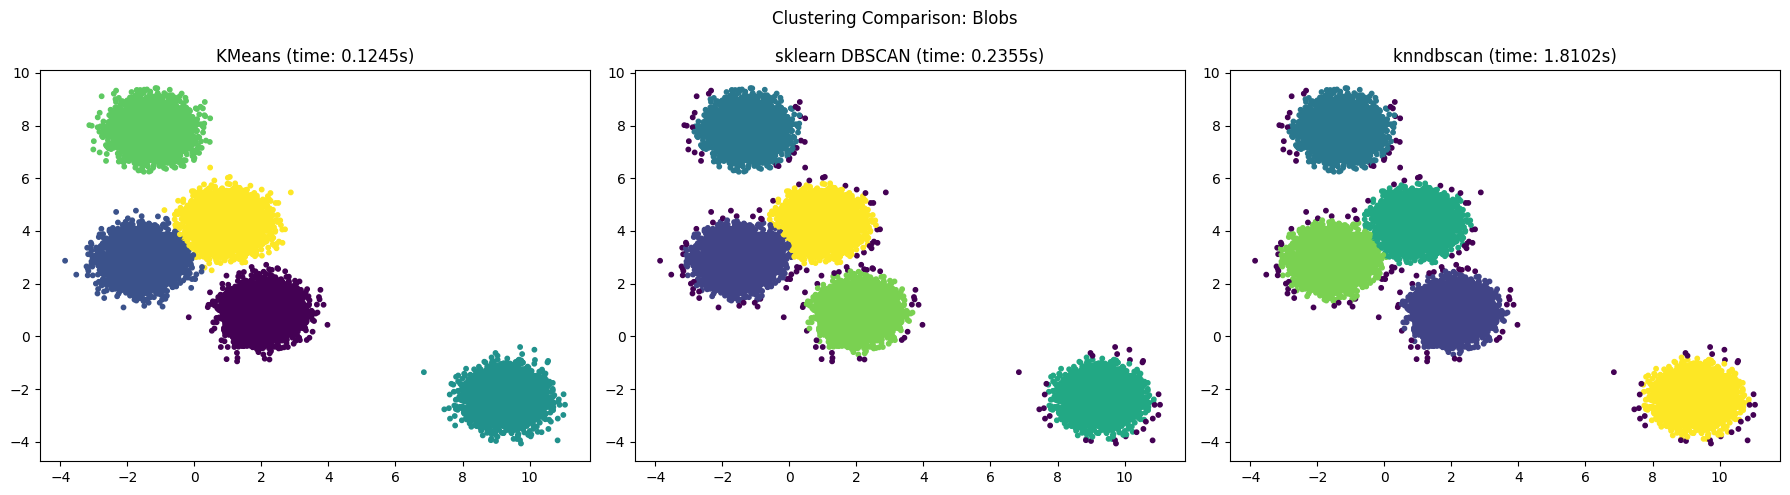

Unique Lables (DBSCAN): [-1  0  1  2  3  4]
Unique Lables (K-NN DBSCAN): [-1  0  1  2  3  4]


In [ ]:
CWD = Path.cwd()
FIG_DIR = CWD / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
n_samples = 30_000
seed = 0

# 1. Blobs
print("Generating Blobs...")
n_blobs = 5
X_blobs, _ = make_blobs(  # type: ignore
    n_samples=n_samples,
    centers=n_blobs,
    cluster_std=0.5,
    random_state=seed,
)
labels_kmeans, labels_dbscan, labels_knn = run_benchmark(
    X_blobs,
    dataset_name="Blobs",
    n_clusters=n_blobs,
    eps=0.5,
    min_samples=100 * 3,
    seed=seed,
    figs_dir=FIG_DIR,
)
print(f"Unique Lables (DBSCAN): {np.unique(labels_dbscan)}")
print(f"Unique Lables (K-NN DBSCAN): {np.unique(labels_knn)}")

# DBSCAN Parameters

- `eps`: Maximum distance between two samples for them to be considered neighbors.
  - Small `eps`: More noise points, fragmented clusters (higher variance / potential overfitting).
  - Large `eps`: Fewer noise points, merged clusters (higher bias / potential underfitting).

- `min_samples`: Minimum number of points within `eps` required for a point to be a core point (density threshold).
  - Small `min_samples`: Easier to form clusters, fewer noise points (higher variance / potential overfitting).
  - Large `min_samples`: Harder to form clusters, more noise points (higher bias / potential underfitting).


Generating Moons...

==================== Benchmarking on Moons ====================
Data shape: (10000, 2)
Running KMeans (k=2)...
Running DBSCAN (sklearn) [eps=0.1, min_samples=120]...
Running knndbscan [eps=0.1, min_samples=120]...

Benchmark Results:
Algorithm              Time (s)   Clusters    Noise Points
------------------------------------------------------------
KMeans                   0.1369          2               0
DBSCAN (sklearn)         0.0555          2               0
knndbscan                0.1628          2               0

Plot saved to /home/prajwal/github-repos/hatann/_experiments/figures/comparison_moons.png


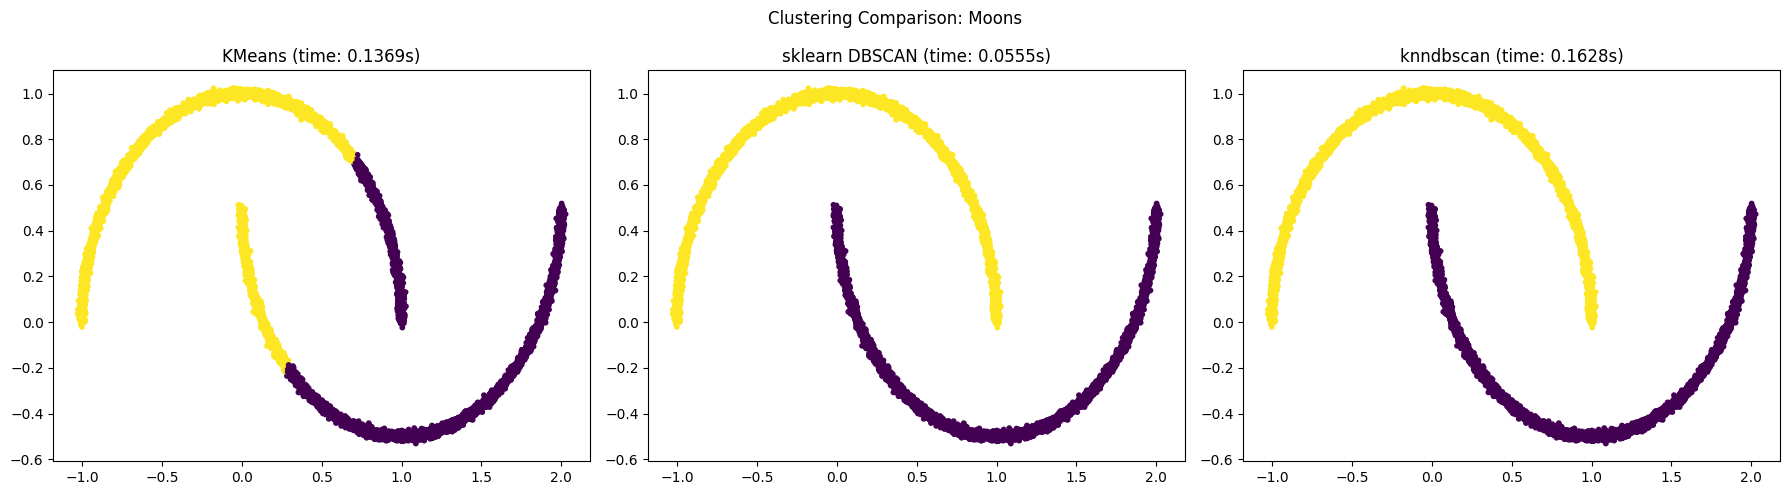

Unique Lables (DBSCAN): [0 1]
Unique Lables (K-NN DBSCAN): [0 1]


In [ ]:
n_samples = 10_000
seed = 0

# 2. Moons
print("Generating Moons...")
X_moons, _ = make_moons(n_samples=n_samples, noise=0.01, random_state=seed)
labels_kmeans, labels_dbscan, labels_knn = run_benchmark(
    X_moons,
    dataset_name="Moons",
    n_clusters=2,
    eps=0.1,
    min_samples=120,
    seed=seed,
    figs_dir=FIG_DIR,
)
print(f"Unique Lables (DBSCAN): {np.unique(labels_dbscan)}")
print(f"Unique Lables (K-NN DBSCAN): {np.unique(labels_knn)}")


==================== Benchmarking on Uniform Random ====================
Data shape: (10000, 2)
Running KMeans (k=7)...
Running DBSCAN (sklearn) [eps=0.271, min_samples=100]...
Running knndbscan [eps=0.271, min_samples=100]...

Benchmark Results:
Algorithm              Time (s)   Clusters    Noise Points
------------------------------------------------------------
KMeans                   0.0820          7               0
DBSCAN (sklearn)         0.0392         13            1951
knndbscan                0.1178         13            1951

Plot saved to /home/prajwal/github-repos/hatann/_experiments/figures/comparison_uniform_random.png


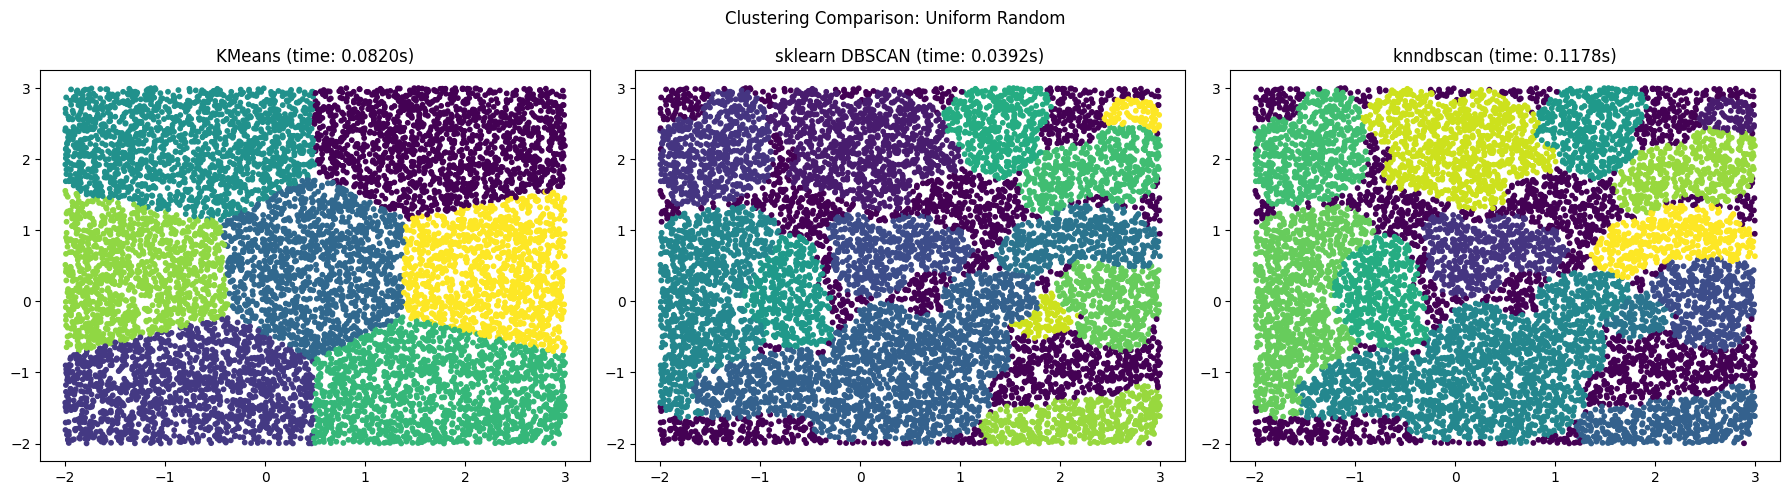

Unique Lables (DBSCAN): [-1  0  1  2  3  4  5  6  7  8  9 10 11 12]
Unique Lables (K-NN DBSCAN): [-1  0  1  2  3  4  5  6  7  8  9 10 11 12]


In [4]:
# generate uniform random points between [-2, 3] in 2D
np.random.seed(seed)
X = np.random.uniform(-2, 3, size=(n_samples, 2))
labels_kmeans, labels_dbscan, labels_knn = run_benchmark(
    X,
    dataset_name="Uniform Random",
    n_clusters=7,  # Not meaningful for uniform data, but required for KMeans
    eps=0.271,
    min_samples=100,
    seed=seed,
    figs_dir=FIG_DIR,
)
print(f"Unique Lables (DBSCAN): {np.unique(labels_dbscan)}")
print(f"Unique Lables (K-NN DBSCAN): {np.unique(labels_knn)}")

# Questions
1. If we use DBSCAN for HATAAN, how do we choose the `eps` and `min_samples` parameters?
   1. For uniform random data, DBSCAN is extremely sensitive to the choice of `eps` and `min_samples`
2. Also a bigger question is how to deal with noise points?
   1. Noisy points will all have the same label (-1) in DBSCAN. The current implementation of HATAAN will treat all noise points as a single cluster, which is not ideal. We need a strategy to handle noise points effectively.
   2. Recluster the noise points using k-means?
3. Once we find concave clusters using DBSCAN, what does it mean for the rest of the algorithm? The current assumptions for estimating the Hessian/Trust Region are based on the clusters being convex.